Quantum Leadership Training Program 2025

# Quantum Teleportation

Kifumi Numata, IBM Quantum (Nov 19, 2025)

### Table of Contents 
- 1. Quantum State Tomography    
    - Exercise 1 - Estimate $r_x$ and $r_y$ value
- 2. Quantum Teleportation
    - Exercise 2 - Build a teleportation circuit
- 3. Superdense Coding
    - Exercise 3 - Use another bell state

In [1]:
# Required packages for Google Colab
#%pip install qiskit[visualization] qiskit-aer qiskit-ibm-runtime

In [2]:
# See the version of Qiskit
import qiskit
qiskit.__version__

'2.2.3'

In [3]:
# Import the qiskit libraty
from qiskit import QuantumCircuit
from qiskit_aer import StatevectorSimulator, AerSimulator
from qiskit.visualization import plot_bloch_multivector, plot_histogram, plot_gate_map, plot_bloch_vector
from qiskit_ibm_runtime import Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.result import marginal_counts

## 1. Quantum State Tomography

An arbitrary quantum state of a qubit is written as

$$|\psi\rangle =\cos\frac{\theta}{2}|0\rangle+e^{i\varphi}\sin\frac{\theta}{2}|1\rangle=
\left(
\begin{matrix}
\cos\frac{\theta}{2}\\
e^{i\varphi}\sin\frac{\theta}{2}
\end{matrix}
\right)
.$$


We can wirte the quantum state $|\psi \rangle$ as its density matrix $\rho$

$$\rho = \frac{1}{2}\bigl( \textbf{I} + (\sin{\theta}\cos{\varphi})\textbf{X}+  (\sin{\theta}\sin{\varphi})\textbf{Y} +  (\cos{\theta})\textbf{Z} \bigr)$$

Or, in general,


$$\rho = \frac{1}{2}(\textbf{I} + r_{x}\textbf{X}+ r_{y}\textbf{Y} + r_{z}\textbf{Z})$$
where
$r_{x}^2+r_{y}^2+r_{z}^2=1$.

And, the Bloch vector is $\textbf{r} = (r_{x}, r_{y}, r_{z})$.

Let's create an arbitrary quantum state using randome number.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
#create a random 1-qubit state from a random (theta, varphi) to define r vector
np.random.seed(1) #fixing seed for repeatibility

theta = np.random.uniform(0.0, 1.0) * np.pi    #from 0 to pi
varphi = np.random.uniform(0.0, 2.0) * np.pi    #from 0 to 2*pi

def get_r_vec(theta, varphi):
    rx = np.sin(theta) * np.cos(varphi)
    ry = np.sin(theta) * np.sin(varphi)
    rz = np.cos(theta)
    return (rx, ry, rz)

# get r vector
rx, ry, rz = get_r_vec(theta, varphi)

print("theta="+str(theta), ",varphi="+str(varphi))
print("(rx, ry, rz) = (" + str(rx) + ", " + str(ry) + ", " + str(rz) + ")")

theta=1.3101132663588946 ,varphi=4.525932273597346
(rx, ry, rz) = (-0.1791150283307452, -0.9494670044331133, 0.2577405946274022)


We can show this bloch vector on the Bloch sphere.

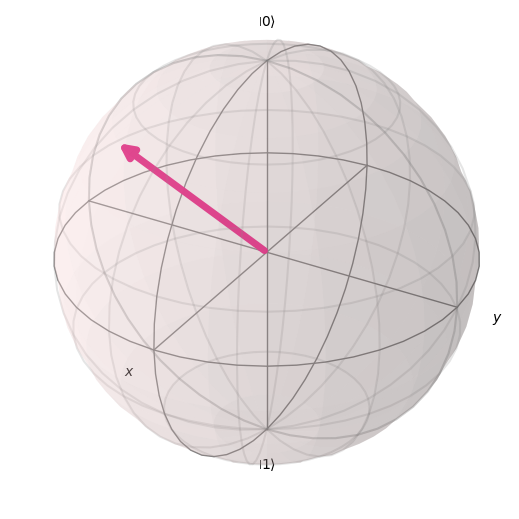

In [5]:
r = [rx, ry, rz]
from qiskit.visualization import plot_bloch_vector
plot_bloch_vector(r)

### Estimate $r_z$ value

In order to estimate $r_z$, we create a quantum state and measure it and then repeat it many times, and then we will take the statistics of the measurement.

For creating the quantum state, we will use $U$ gate with the parameter, $ \theta, \varphi$. (Please refer [U-gate](https://qiskit.org/documentation/stubs/qiskit.circuit.library.UGate.html) document.)

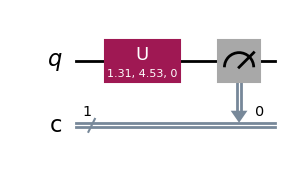

In [6]:
from qiskit import QuantumCircuit

#create a 1-qubit quantum state psi from theta, varphi parameters
qc = QuantumCircuit(1, 1)
qc.u(theta, varphi, 0.0, 0)

#measure in computational basis
qc.measure(0,0)

qc.draw(output="mpl")

Using `AerSimulator`, we will mesure it in the computational basis to estimate $r_z$.

{'0': 647, '1': 353}


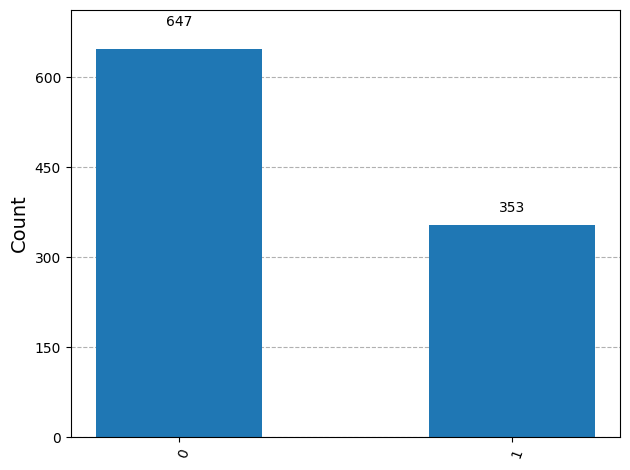

In [7]:
# see if the expected value of measuring in the computational basis
# approaches the limit of rz
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import Sampler

# Define backend
backend = AerSimulator()
nshots = 1000 # or 10000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=nshots)
result = job.result()

# Extract counts data
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
from qiskit.visualization import plot_histogram
plot_histogram(counts)

In [8]:
rz_approx = (counts['0'] - counts['1'])/nshots

print("rz = ", rz, " and approx of rz = ", rz_approx)

rz =  0.2577405946274022  and approx of rz =  0.294


Using Quantum State Tomography method, we estimated the $r_z$ value.

## Exercise 1 - Estimate $r_x$ and $r_y$ value
Build the code to estimate the value of $r_x$ in the quantum state tomography.

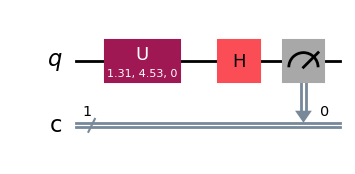

In [9]:
#create a 1-qubit quantum state psi from theta, varphi parameters
qc = QuantumCircuit(1, 1)
qc.u(theta, varphi, 0.0, 0)

##your code goes here##
qc.h(0)
qc.measure(0,0)

qc.draw(output="mpl")

{'0': 4158, '1': 5842}


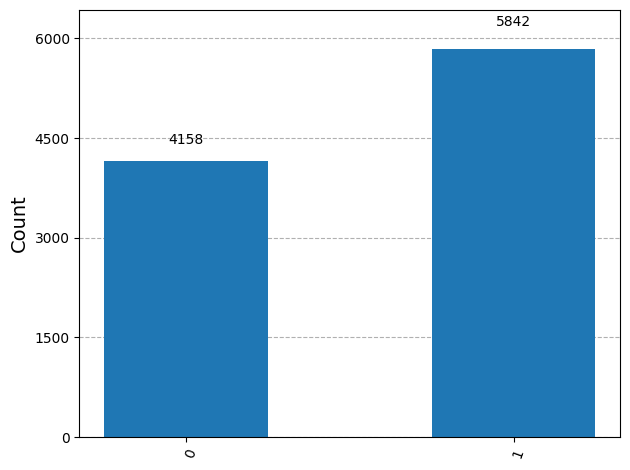

In [10]:
# Define backend
backend = AerSimulator()
nshots = 10000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=nshots)
result = job.result()

# Extract counts data
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

In [11]:
rx_approx = (counts['0'] - counts['1'])/nshots

print("rx = ", rx, " and approx of rx = ", rx_approx)

rx =  -0.1791150283307452  and approx of rx =  -0.1684


Build the code to estimate the value of $r_y$ in the quantum state tomography.    
For more information about the various gates, please refer [this](https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.QuantumCircuit#sdg).

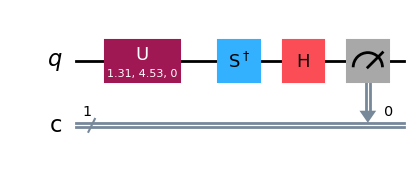

In [12]:
#create a 1-qubit quantum state psi from theta, varphi parameters
qc = QuantumCircuit(1, 1)
qc.u(theta, varphi, 0.0, 0)

##your code goes here##
qc.sdg(0)
qc.h(0)
qc.measure(0,0)

qc.draw(output="mpl")

{'1': 9739, '0': 261}


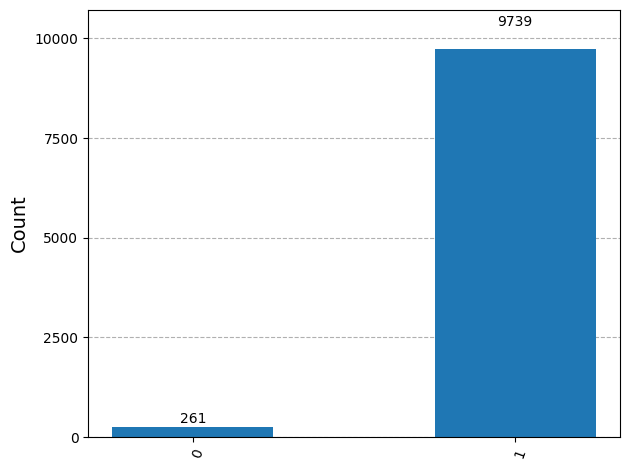

In [13]:
# Define backend
backend = AerSimulator()
nshots = 10000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=nshots)
result = job.result()

# Extract counts data
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

In [14]:
ry_approx = (counts['0'] - counts['1'])/nshots

print("ry = ", ry, " and approx of ry = ", ry_approx)

ry =  -0.9494670044331133  and approx of ry =  -0.9478


In [15]:
print("Estimated vector is (", rx_approx,",",ry_approx,",",rz_approx,").")
print("Original random vector was (" + str(rx) + ", " + str(ry) + ", " + str(rz) + ").")

Estimated vector is ( -0.1684 , -0.9478 , 0.294 ).
Original random vector was (-0.1791150283307452, -0.9494670044331133, 0.2577405946274022).


You got the estimation value of the original random vector using this quantum sate tomography method.

## 2. Quantum Teleportation

To build the Quantum Teleportation circuit, we need three qubits: two for the entangled pair shared by Alice and Bob, and one for the unknown quantum state $|\psi\rangle$.

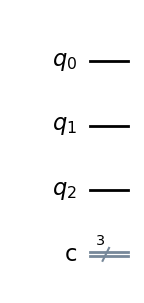

In [16]:
# create 3-qubits circuit
qc = QuantumCircuit(3,3)

qc.draw(output="mpl")

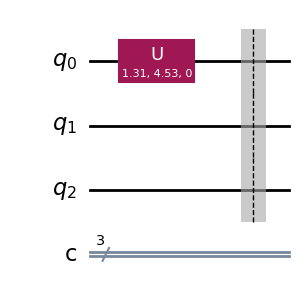

In [17]:
# Alice creates an unknown quantum state using the u-gate.
qc.u(theta, varphi, 0.0, 0)
qc.barrier()    # for visual separation

qc.draw(output="mpl")

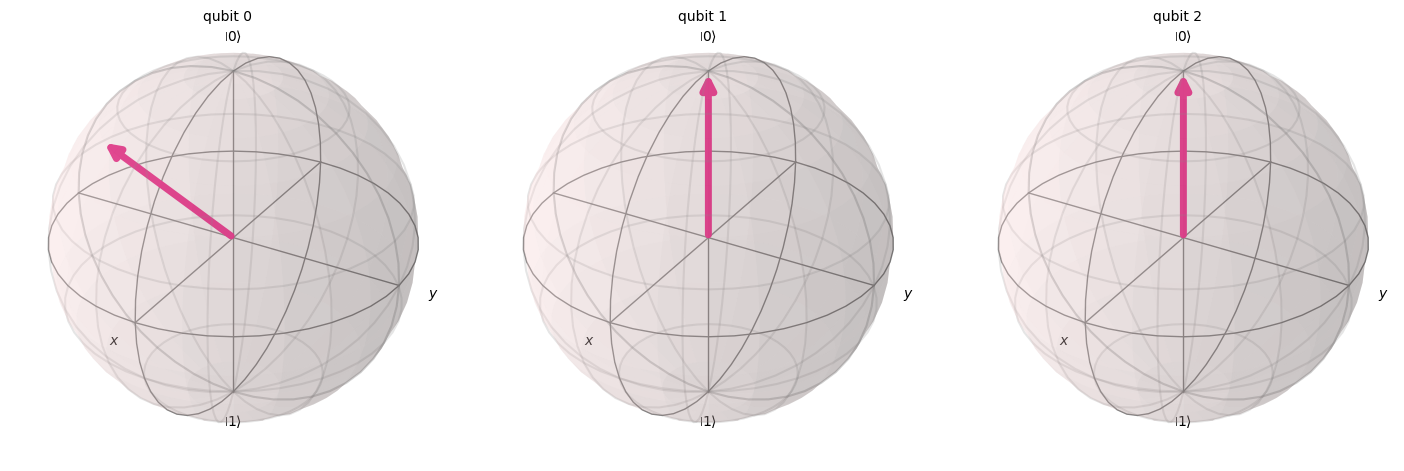

In [18]:
# show the quantum state on bloch sphere
from qiskit.quantum_info import Statevector
out_vector = Statevector(qc)

from qiskit.visualization import plot_bloch_multivector
plot_bloch_multivector(out_vector)

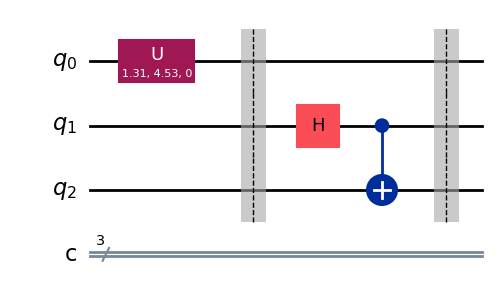

In [19]:
# Eve creates an EPR pair, send one qubit to Alice and the other to Bob.
qc.h(1)
qc.cx(1, 2)
qc.barrier()    # for visual separation

qc.draw(output="mpl")

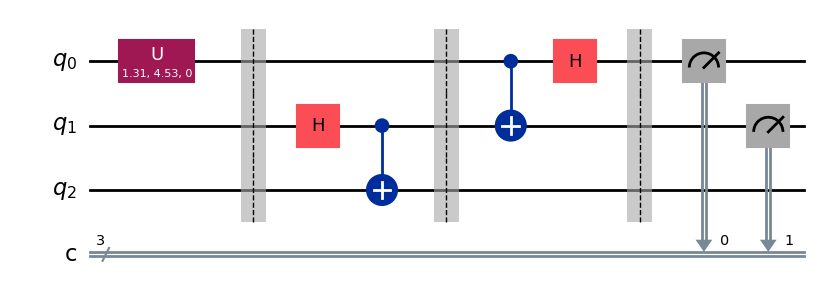

In [20]:
# Alice entangles the unknown state with her EPR part, using the CNOT gate & H gate.
qc.cx(0, 1)
qc.h(0)
qc.barrier()

# Alice measures the two qubits.
qc.measure(0, 0)
qc.measure(1, 1)

qc.draw(output="mpl")

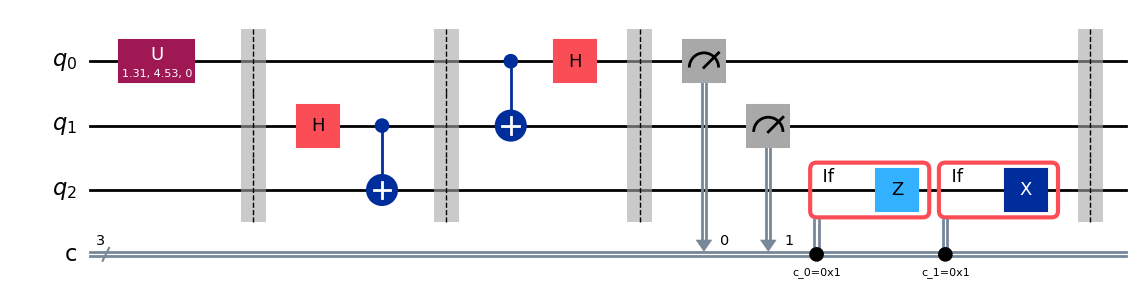

In [21]:
# Alice sent the results to Bob. Now, Bob applies correction
with qc.if_test((0, 1)):
    qc.z(2)
with qc.if_test((1, 1)):
    qc.x(2)
qc.barrier()

qc.draw(output="mpl")

You have completed to build the quantum teleportation circuit! Let's see the output state of this circuit using the statevector simulator.

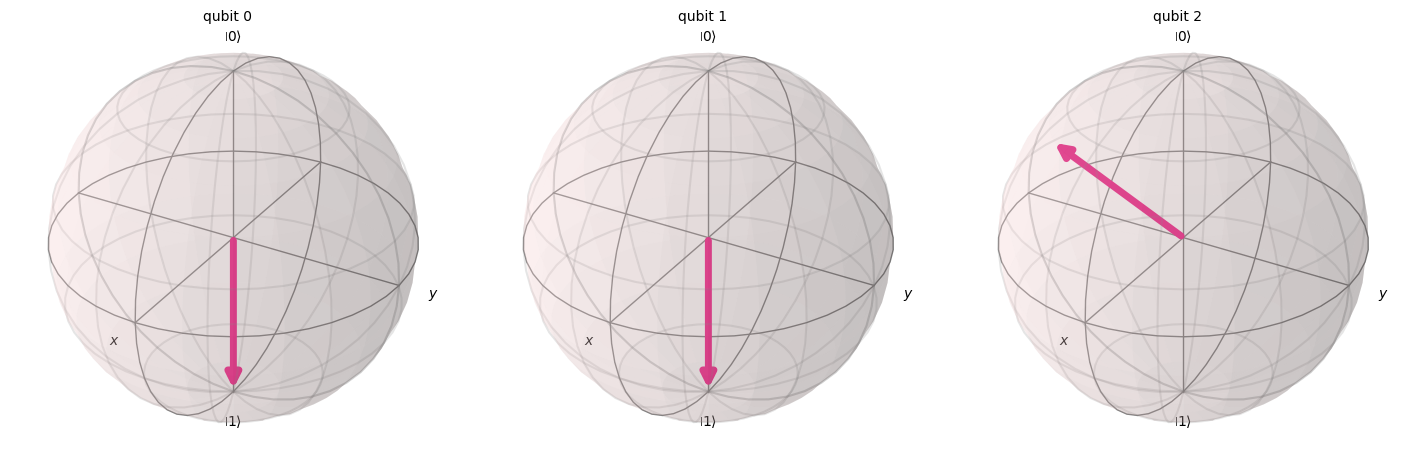

In [22]:
from qiskit_aer import StatevectorSimulator
backend = StatevectorSimulator()
out_vector = backend.run(qc, shots=1).result().get_statevector()    # set shots = 1

plot_bloch_multivector(out_vector)

You can see that the quantum state created by u-gate of qubit 0 has been transferred to qubit 2.

You can run above cell a few times to make sure. You may notice that the qubits 0 & 1 change states, but qubit 2 is always in the state $|\psi\rangle $.

### Confirm the result by applying U inverse.

To check if the quantum state has been teleported correctly, we apply the inverse of u-gate on Bob's qubit so that we can measure '0'.

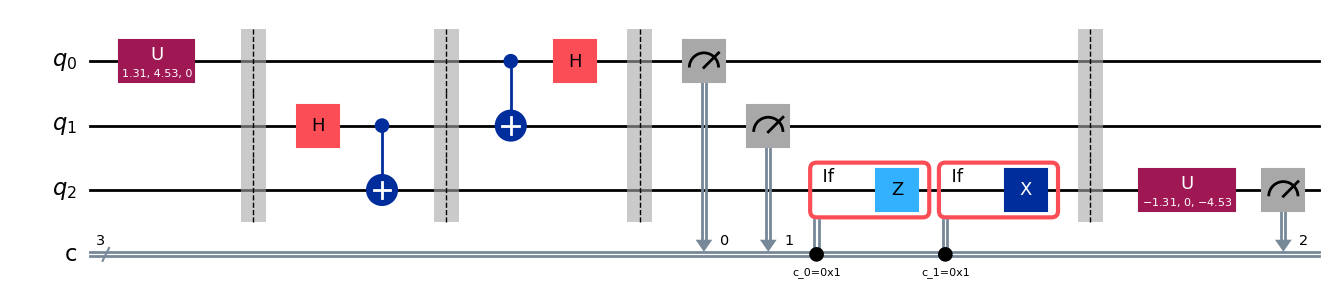

In [23]:
# Apply the inverse of u-gate to measure |0>
qc.u(theta, varphi, 0.0, 2).inverse()    # inverse of u(theta,varphi,0.0)
qc.measure(2, 2) # add measurement gate

qc.draw(output="mpl")

First, we will execute the circuit using AerSimulator.

{'000': 2474, '010': 2490, '011': 2477, '001': 2559}


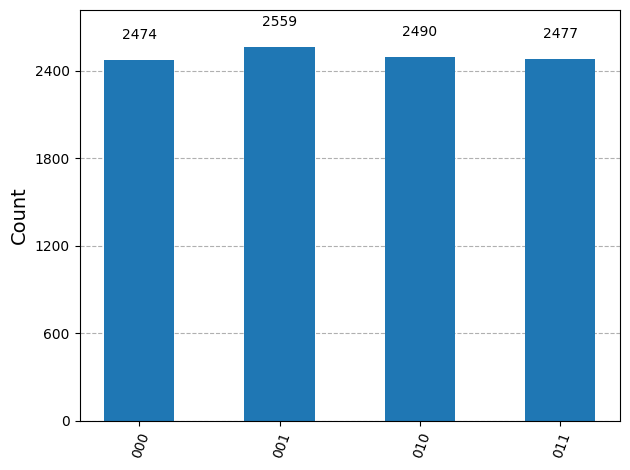

In [24]:
# Define backend
backend_sim = AerSimulator()

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend_sim)
job = sampler.run([isa_qc], shots=10000)
result = job.result()

# Extract counts data
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

We can see we have a 100% chance of measuring $q_2$ (the leftmost bit) in the state $|0\rangle $. This is the expected result, and indicates the teleportation protocol has worked properly.

### Teleportation on a Real Quantum Computer


Next, we will perform it on the real qunatum device. Using the dynamic circuit function, we can operate mid-circuit measurements and real-time conditinals operations in the teleportation circuit.  And now, we will follow 4 steps of Qiskit Patterns.

    1. Map the problem to a quantum-native format
    2. Optimize the circuits
    3. Execute the target circuit
    4. Postprocess the results

## Exercise 2: Build a teleportation circuit

Let's build whole teleportation circuit! It's just coding for practice.

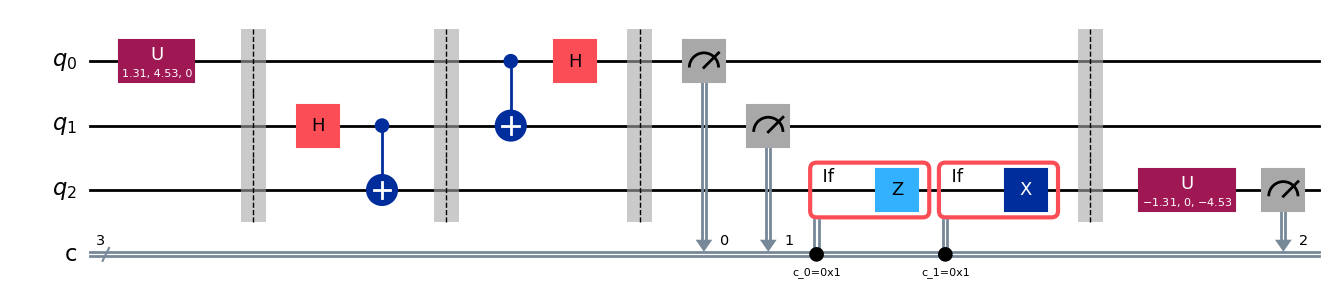

In [25]:
# Step 1: Map the problem to a quantum-native format
# Create the circuit with 3-qubits and 1-bit
qc = QuantumCircuit(3,3)

# Alice creates an unknown quantum state using the u-gate.
qc.u(theta, varphi, 0.0, 0)
qc.barrier()    # for visual separation

# Eve creates EPR pair and sends q1 to Alice and q2 to Bob
##your code goes here##
qc.h(1)
qc.cx(1, 2)
qc.barrier()

# Alice entangles the unknown state with her EPR part, using the CNOT gate & H gate.
##your code goes here##
qc.cx(0, 1)
qc.h(0)
qc.barrier()

# Alice measures the two qubits.
##your code goes here##
qc.measure(0, 0)
qc.measure(1, 1)

# Alice sent the results to Bob. Now, Bob applies correction
##your code goes here##
with qc.if_test((0, 1)):
    qc.z(2)
with qc.if_test((1, 1)):
    qc.x(2)
qc.barrier()

# Apply the inverse of u-gate to measure |0>
qc.u(theta, varphi, 0.0, 2).inverse()
qc.measure(2, 2)

qc.draw(output="mpl")

By applying the inverse of u-gate, you can measure 0.

In [29]:
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(name = "qltp")
service.backends()

[<IBMBackend('ibm_pittsburgh')>,
 <IBMBackend('ibm_fez')>,
 <IBMBackend('ibm_torino')>,
 <IBMBackend('ibm_kingston')>,
 <IBMBackend('ibm_marrakesh')>]

In [30]:
backend = service.least_busy(operational=True)
print("The least busy device is ", backend)

The least busy device is  <IBMBackend('ibm_fez')>


In [31]:
# You can specifiy the device
backend = service.backend('ibm_fez')

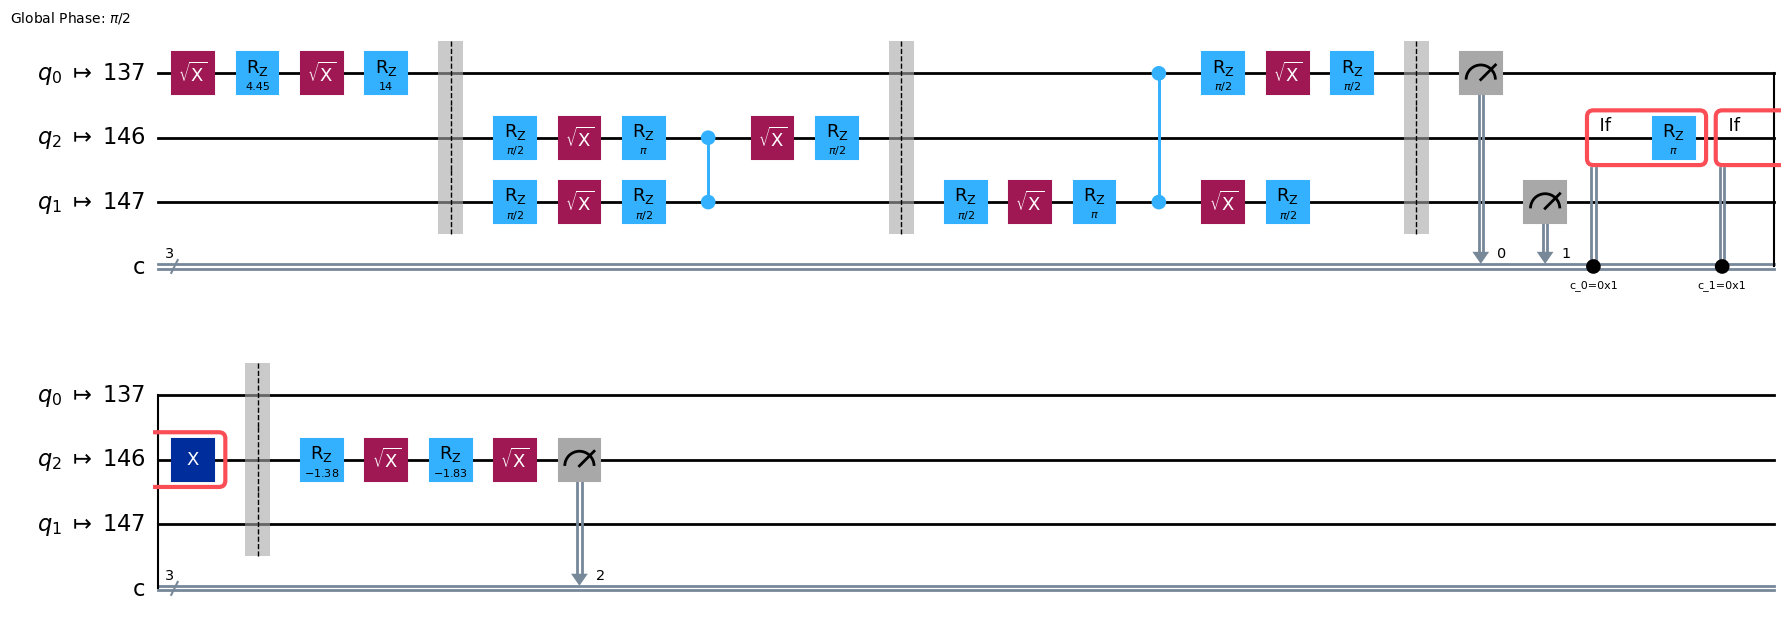

In [32]:
# Step 2: Optimize the circuits
# Transpile the circuit into basis gates executable on the hardware

pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
qc_compiled = pm.run(qc)

qc_compiled.draw("mpl", idle_wires=False)

In [33]:
# Step 3: Execute the target circuit
sampler = Sampler(backend)
job = sampler.run([qc_compiled])

print("job id:", job.job_id())

job id: d4d7fv16dsss73b3tdkg


In [34]:
# Check the job status
job.status()

'RUNNING'

You can also check the job status from your IBM Quantum Dashboard：https://quantum.cloud.ibm.com/workloads

In [35]:
# If the Notebook session got disconnected you can also check your job statuse by running the following code
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(name="qltp")
job_real = service.job('d4d7fv16dsss73b3tdkg') # Input your job-id between the quotations
job_real.status()

'DONE'

In [36]:
# Execute after 'DONE' is displayed
result_real = job_real.result()
print(result_real[0].data.c.get_counts())

{'001': 937, '010': 861, '000': 879, '101': 148, '011': 890, '111': 134, '100': 133, '110': 114}


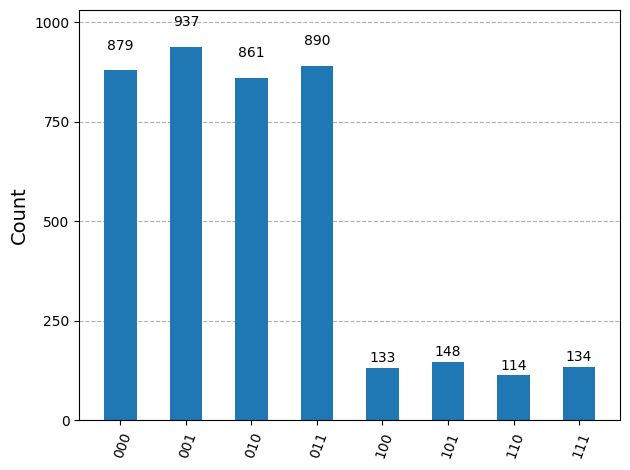

In [37]:
# Step 4: Postprocess the results
from qiskit.visualization import plot_histogram
plot_histogram(result_real[0].data.c.get_counts())

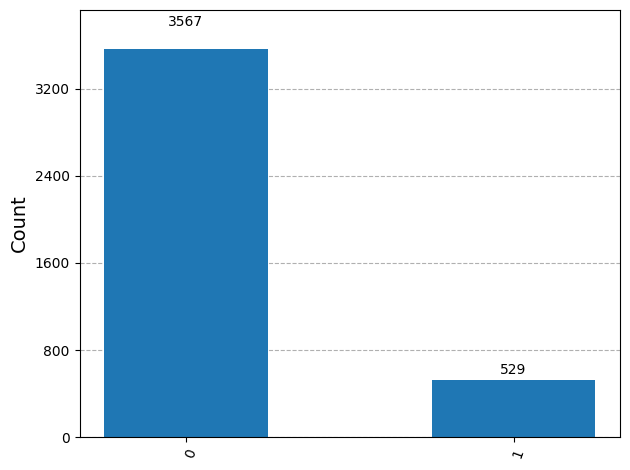

In [39]:
# trace out Bob's results on qubit 2
from qiskit.result import marginal_counts
bobs_qubit = 2
real_counts = result_real[0].data.c.get_counts()
bobs_counts = marginal_counts(real_counts, [bobs_qubit])
plot_histogram(bobs_counts)

As we see here, there are a few results in which we measured $|1 \rangle$. These are due to errors in the gates and qubit decoherence. In particular, Dynamic Circuits tend to have a higher error rate because of the time-consuming measurement in the middle of the circuit.

## 3. Superdense coding

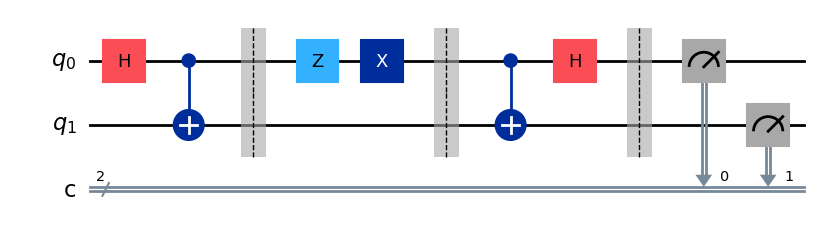

In [27]:
# Step 1: Map the problem to a quantum-native format
# Create 2-qubits circuit
from qiskit import QuantumCircuit
qc=QuantumCircuit(2,2)

# Eve creates EPR pair and send q0 to Alice and q1 to Bob
qc.h(0)
qc.cx(0,1)
qc.barrier()

# set message which Alice wants to transform to Bob
msg = "11"    # You can change the message 

if msg == "00":
    pass
elif msg == "10":    
    qc.x(0)
elif msg == "01":    
    qc.z(0)
elif msg == "11":    
    qc.z(0)
    qc.x(0)
    
qc.barrier()   
# Bob receives EPR qubit from Alice and performs unitery operations
qc.cx(0,1)
qc.h(0)
qc.barrier()

# Bob measures q0 and q1
qc.measure(0,0)
qc.measure(1,1)

qc.draw(output="mpl")

In [28]:
# Step 2: Optimize the circuits
# For this example, the circuit and operators are simple, so no optimizations are needed.

# Step 3: Execute the target circuit
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import Sampler

# Define backend
backend_sim = AerSimulator()
shots=1000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend_sim)
job_sim = sampler.run([isa_qc], shots=shots)
result_sim = job_sim.result()

# Extract counts data
counts = result_sim[0].data.c.get_counts()
print(counts)

{'11': 1000}


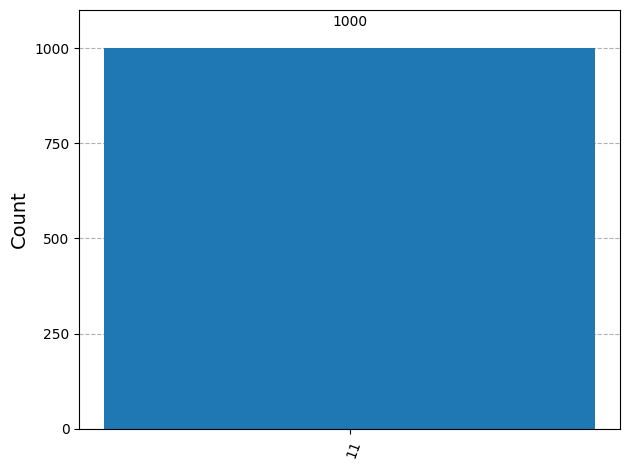

In [30]:
# Step 4: Postprocess the results
from qiskit.visualization import plot_histogram
plot_histogram(counts)

In [31]:
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(name = "qltp")
service.backends()

[<IBMBackend('ibm_fez')>,
 <IBMBackend('ibm_pittsburgh')>,
 <IBMBackend('ibm_torino')>,
 <IBMBackend('ibm_kingston')>,
 <IBMBackend('ibm_marrakesh')>]

In [32]:
backend = service.least_busy(operational=True)
print("The least busy device is ", backend)

The least busy device is  <IBMBackend('ibm_fez')>


In [33]:
# You can specifiy the device
backend = service.backend('ibm_kingston')

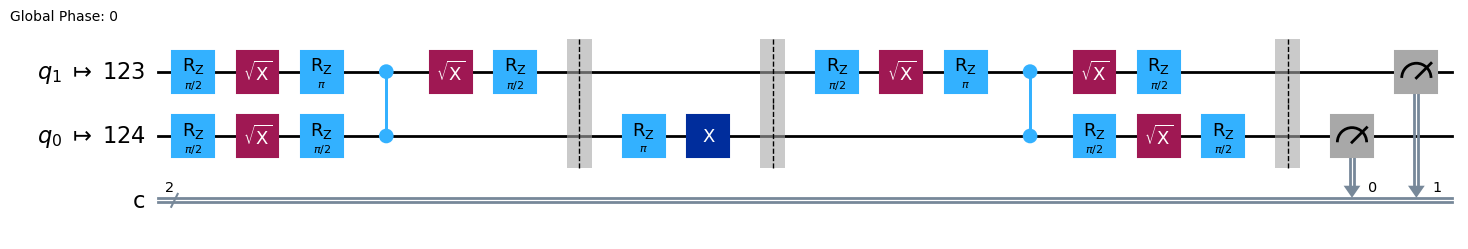

In [43]:
# Step 2: Optimize the circuits
# Transpile the circuit into basis gates executable on the hardware
pm = generate_preset_pass_manager(backend=backend, optimization_level=2)
qc_compiled = pm.run(qc)

qc_compiled.draw("mpl", idle_wires=False)

In [44]:
# Step 3:Execute the target circuit
sampler = Sampler(backend)
job = sampler.run([qc_compiled])
print("job id:", job.job_id())

job id: d4d7ghsl291s73e798b0


In [45]:
# Check the job status
job.status()

'RUNNING'

In [46]:
# If the Notebook session got disconnected you can also check your job statuse by running the following code
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(name = "qltp")  
job = service.job('d4d7ghsl291s73e798b0') # Input your job-id between the quotations
job.status()

'DONE'

In [47]:
# Execute after 'DONE' has been shown
real_result= job.result()
print(real_result[0].data.c.get_counts())

{'11': 3934, '00': 19, '01': 79, '10': 64}


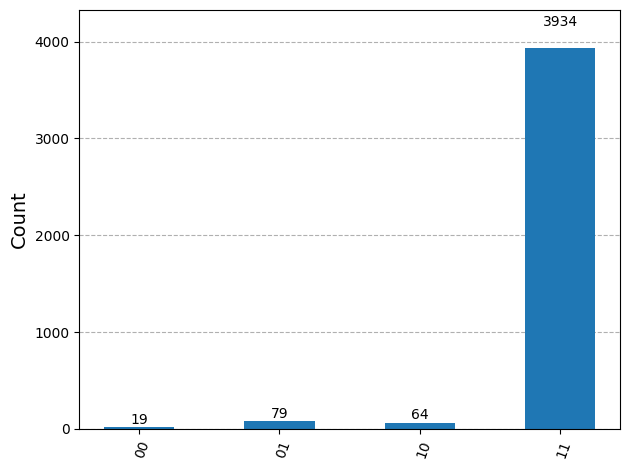

In [48]:
# Step 4: Postprocess the results
from qiskit.visualization import plot_histogram
plot_histogram(real_result[0].data.c.get_counts())

The result using the real device was better than that of quantum teleportation. We will learn more about these errors in later lectures.

## Exercise 3: Use another bell state

We used Bell state, $\left|\Psi^{+}\right\rangle$, in the superdense coding code above. Is it possible to use another Bell state, $\left|\Psi^{-}\right\rangle$? How about $\left|\Phi^{+}\right\rangle$ or $\left|\Phi^{-}\right\rangle$? Let's check if we can build the superdense coding code using $\left|\Psi^{-}\right\rangle$.

$$\left|\Psi^{+}\right\rangle = \frac{1}{\sqrt{2}}(|00\rangle+|11\rangle)$$
$$\left|\Psi^{-}\right\rangle = \frac{1}{\sqrt{2}}(|00\rangle+|11\rangle)$$
$$\left|\Phi^{+}\right\rangle = \frac{1}{\sqrt{2}}(|01\rangle+|10\rangle)$$
$$\left|\Phi^{-}\right\rangle = \frac{1}{\sqrt{2}}(|01\rangle-|10\rangle)$$

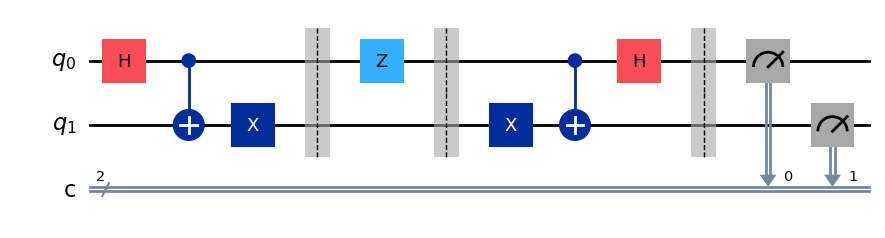

In [43]:
from qiskit import QuantumCircuit
# Step 1: Map the problem to a quantum-native format
# Create 2-qubits circuit
qc=QuantumCircuit(2,2)

# Eve creates EPR pair and send q0 to Alice and q1 to Bob
qc.h(0)
qc.cx(0,1)
qc.x(1)
qc.barrier()

# set message which Alice wants to transform to Bob
msg = "01"    # You can change the message 

if msg == "00":
    pass
elif msg == "10":    
    qc.x(0)
elif msg == "01":    
    qc.z(0)
elif msg == "11":    
    qc.z(0)
    qc.x(0)
    
qc.barrier()   
# Bob receives EPR qubit from Alice and performs unitery operations
qc.x(1)
qc.cx(0,1)
qc.h(0)
qc.barrier()

# Bob measures q0 and q1
qc.measure(0,0)
qc.measure(1,1)

qc.draw(output="mpl")

In [44]:
# Step 2: Optimize the circuits
# For this example, the circuit and operators are simple, so no optimizations are needed.

# Step 3: Execute the target circuit
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import Sampler

# Define backend
backend_sim = AerSimulator()
shots=1000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend_sim)
job_sim = sampler.run([isa_qc], shots=shots)
result_sim = job_sim.result()

# Extract counts data
counts = result_sim[0].data.c.get_counts()
print(counts)

{'01': 1000}


## Exercise 3: Use another bell state

We used Bell state $\left|\Psi^{+}\right\rangle$ as EPR pair in the superdense coding code above. Is it possible to use another Bell state $\left|\Psi^{-}\right\rangle$ as EPR pair? How about $\left|\Phi^{+}\right\rangle$ or $\left|\Phi^{-}\right\rangle$? Let's check if we can build the superdense coding code using $\left|\Psi^{-}\right\rangle$.

$$\left|\Psi^{+}\right\rangle = \frac{1}{\sqrt{2}}(|00\rangle+|11\rangle)$$
$$\left|\Psi^{-}\right\rangle = \frac{1}{\sqrt{2}}(|00\rangle-|11\rangle)$$
$$\left|\Phi^{+}\right\rangle = \frac{1}{\sqrt{2}}(|01\rangle+|10\rangle)$$
$$\left|\Phi^{-}\right\rangle = \frac{1}{\sqrt{2}}(|01\rangle-|10\rangle)$$

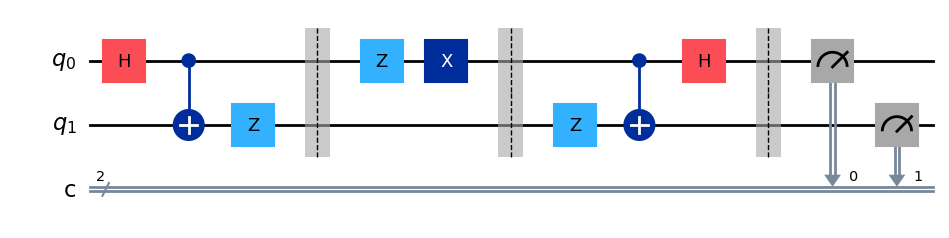

In [45]:
from qiskit import QuantumCircuit
# Step 1: Map the problem to a quantum-native format
# Create 2-qubits circuit
qc=QuantumCircuit(2,2)

# Eve creates EPR pair and send q0 to Alice and q1 to Bob
qc.h(0)
qc.cx(0,1)
qc.z(1)
qc.barrier()

# set message which Alice wants to transform to Bob
msg = "11"    # You can change the message 

if msg == "00":
    pass
elif msg == "10":    
    qc.x(0)
elif msg == "01":    
    qc.z(0)
elif msg == "11":    
    qc.z(0)
    qc.x(0)
    
qc.barrier()   
# Bob receives EPR qubit from Alice and performs unitery operations
qc.z(1)
qc.cx(0,1)
qc.h(0)
qc.barrier()

# Bob measures q0 and q1
qc.measure(0,0)
qc.measure(1,1)

qc.draw(output="mpl")

In [46]:
# Step 2: Optimize the circuits
# For this example, the circuit and operators are simple, so no optimizations are needed.

# Step 3: Execute the target circuit
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import Sampler

# Define backend
backend_sim = AerSimulator()
shots=1000

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)
isa_qc = pm.run(qc)

# Run the job
sampler = Sampler(mode=backend_sim)
job_sim = sampler.run([isa_qc], shots=shots)
result_sim = job_sim.result()

# Extract counts data
counts = result_sim[0].data.c.get_counts()
print(counts)

{'11': 1000}
